In [1]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
from sklearn.cluster import KMeans
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
from collections import Counter
from threadpoolctl import threadpool_info, threadpool_limits
from sklearn.decomposition import PCA
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [2]:
split_thres = (0.4, 0.6)
addon = 'unfiltered'
downlims = [5,3,5]
load_data=True
train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, 
                                                          downlims)

Loaded successfully


In [3]:
train_condensed = get_extended_condensed_data(train_scaled)

In [4]:
sw_train = get_sleep_state_conversion(train_scaled)
sw_train_condensed = get_extended_condensed_data(sw_train)

In [5]:
def perform_pca_by_grouping(df, condensed_df, num_components=2, **grouping_vars):
    groupings, group_labels, genos, ages, regions, nts = get_cell_groupings(condensed_df, **grouping_vars)
    output = {}
    spike_matrix = ['ifr', 'mean_isis', 'median_isis', 'max_isis', 'min_isis', 'sd', 'cv', 'cv2', 'lv', 'lvr']
    for i, group in enumerate(groupings):
        use_cells = df[df.cell.isin(group)]
        pca = PCA(n_components=num_components)
        X_pca = pca.fit_transform(use_cells[spike_matrix])
        print(pca.score(use_cells[spike_matrix]))
        output[group_labels[i]] = {"PCA":X_pca, "state":list(use_cells['state'])}
    return output

def perform_pca_by_neuron(df, spec_cells = [], num_components=2):
    output = {}
    spike_matrix = ['ifr', 'mean_isis', 'median_isis', 'max_isis', 'min_isis', 'sd', 'cv', 'cv2', 'lv', 'lvr']
    if not spec_cells:
        use_cells = df.cell.unique()
    else: use_cells = spec_cells
    grouped = df.groupby(df.cell)
    for cell in tqdm(use_cells):
        pca = PCA(n_components=num_components)
        X_pca = pca.fit_transform(grouped.get_group(cell)[spike_matrix])
        out = grouped.get_group(cell)
        out['PCA'] = [i for i in X_pca]
        output[cell] = out
    return output   

In [6]:
example_neuron = perform_pca_by_neuron(train_scaled, spec_cells = ['caf69_358_1228_0_12_0_wt'])

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 10.84it/s]


In [10]:
grouped = perform_pca_by_grouping(train_scaled, train_condensed, by_animal=True)

-10.395341384410356
-10.587411548070973
-10.51183675832144
-10.358327328550965
-10.6628485086982
-10.611870286402498
-10.383564375677704
-10.370841914931335
-10.249010068172183
-10.59211900284758
-10.748936533959059
-10.568010251137505
-10.97097089820853
-10.774891507187643
-10.580821048509216
-10.32182678817246
-10.648408116039626


In [8]:
def graph_pca_layout_by_state(dictionary):
    fig, ax = plt.subplots(len(dictionary), 1, figsize=(12, 5*len(dictionary)))
    for i, [name, df] in tqdm(enumerate(dictionary.items())):
        plt.subplot(len(dictionary), 1,i+1)
        plt.scatter([x[0] for x in df['PCA']], [x[1] for x in df['PCA']], c=df['state'],
                    cmap='coolwarm', edgecolor='k', s=80)
        plt.xlabel('Principal Component 1')
        plt.ylabel('Principal Component 2')
        plt.title(name)
        plt.colorbar(label='Target classes')
    plt.tight_layout()

17it [00:06,  2.70it/s]


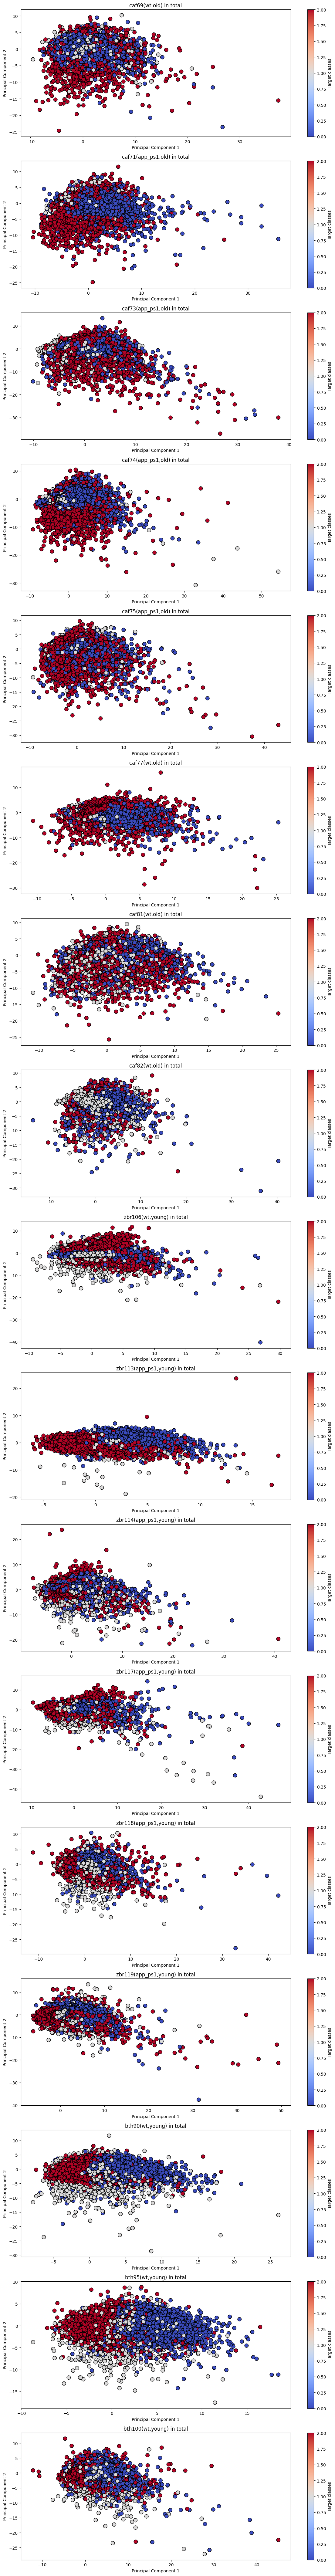

In [11]:
graph_pca_layout_by_state(grouped)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:00<00:00, 94.72it/s]
20it [00:00, 92.68it/s]


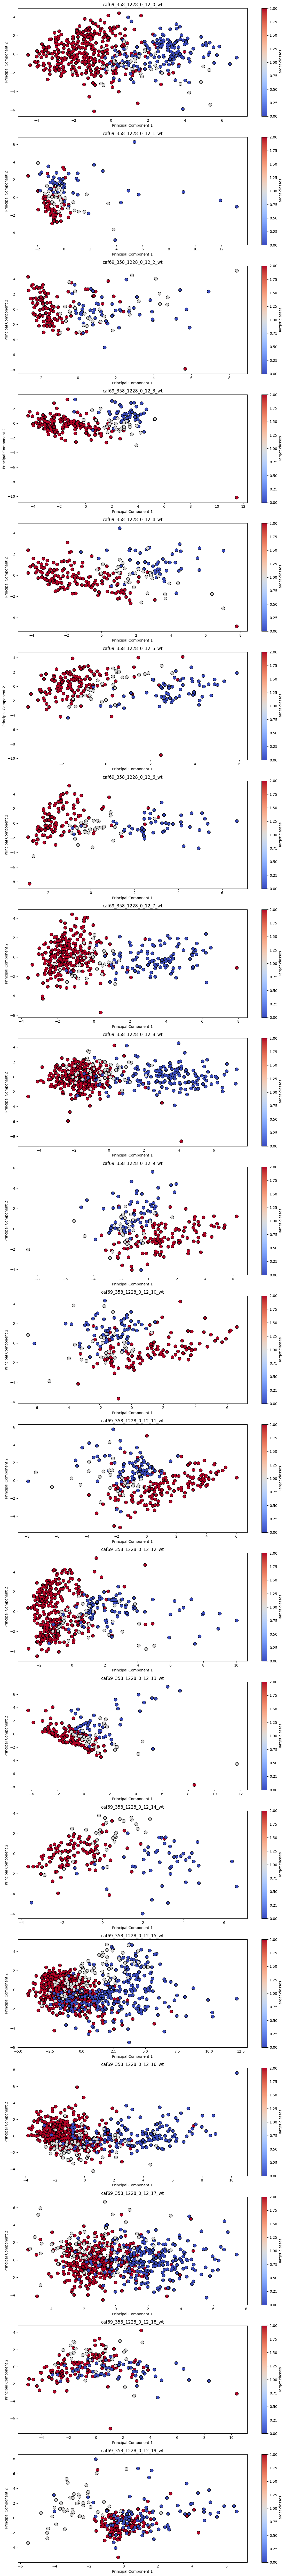

In [ ]:
strings = []
for i in range(20):
    strings.append(f'caf69_358_1228_0_12_{i}_wt')
neurons = perform_pca_by_neuron(train_scaled, spec_cells = strings)
graph_pca_layout_by_state(neurons)

1it [00:00, 41.67it/s]


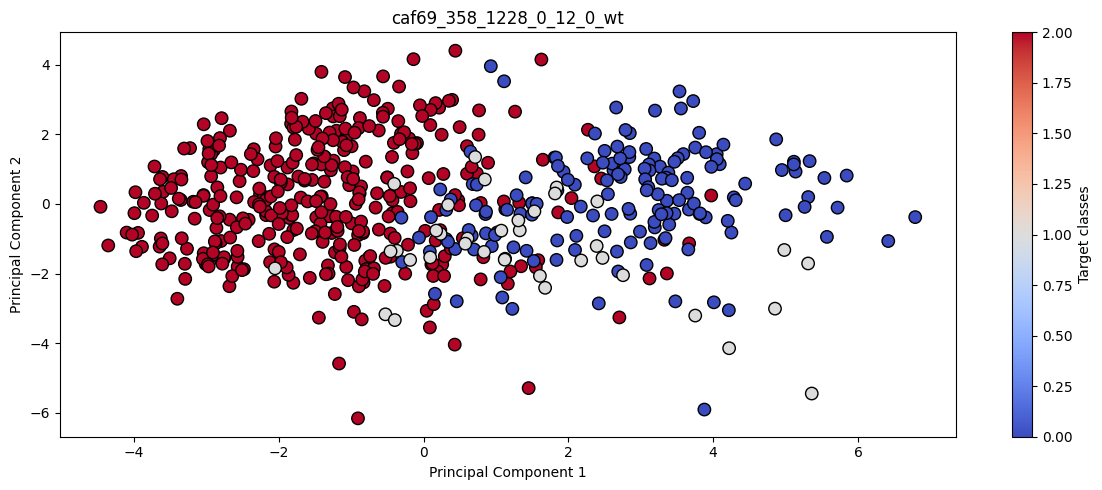

In [13]:
graph_pca_layout_by_state(example_neuron)

In [19]:
perform_pca_by_grouping(sw_train, sw_train_condensed, by_geno=True, by_animal=True)

-10.395341384410356
-10.587411548070973
-10.51183675832144
-10.358327328550965
-10.6628485086982
-10.611870286402498
-10.383564375677704
-10.370841914931335
-10.249010068172183
-10.59211900284758
-10.748936533959059
-10.568010251137505
-10.97097089820853
-10.774891507187643
-10.580821048509216
-10.32182678817246
-10.648408116039626


{'caf69(wt,old) in total': array([[ 0.99955803,  1.09065397],
        [-0.82915177,  0.37835929],
        [ 0.49186793,  2.71324238],
        ...,
        [-0.30094167,  0.00642948],
        [ 2.60233169,  2.83467496],
        [ 0.71078075,  0.29314861]], shape=(175981, 2)),
 'caf71(app_ps1,old) in total': array([[-1.41447558,  0.3231668 ],
        [ 0.40086031,  0.83757363],
        [-1.53253563, -1.07170922],
        ...,
        [ 1.47087859, -0.69518525],
        [-3.14197628, -0.04606468],
        [ 0.29301615,  0.6001955 ]], shape=(80353, 2)),
 'caf73(app_ps1,old) in total': array([[-2.22373021, -0.54339569],
        [-4.06283858, -3.11432509],
        [-0.36912535, -0.96868079],
        ...,
        [ 2.06295231, -0.21077436],
        [ 2.51465474, -2.53707285],
        [ 0.21829434,  2.819029  ]], shape=(173329, 2)),
 'caf74(app_ps1,old) in total': array([[-1.62169544, -2.12696   ],
        [-1.31356336, -0.57506476],
        [-0.8706349 ,  1.49528184],
        ...,
        [-1

In [54]:
y = using_arr['state']

In [58]:
num_points = [0,100000000]

In [63]:
kmeans = KMeans(2)

In [64]:
with threadpool_limits(limits=4):
    kmeans.fit(X_pca[num_points[0]:num_points[1]])

In [65]:
print(kmeans.cluster_centers_)

[[ 2.34342658  0.15624889]
 [-1.33697394 -0.08914326]]


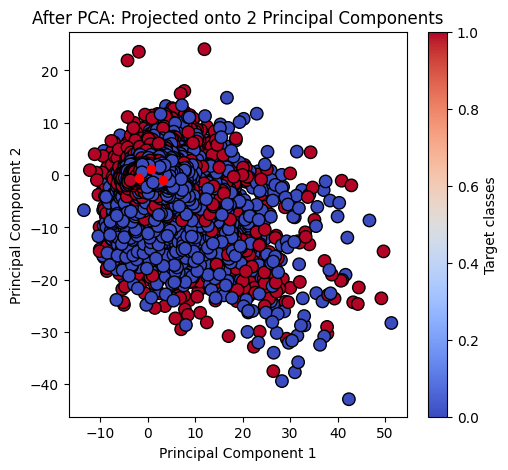

In [62]:

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 2)
plt.scatter(X_pca[num_points[0]:num_points[1], 0], X_pca[num_points[0]:num_points[1], 1], c=y[num_points[0]:num_points[1]],
            cmap='coolwarm', edgecolor='k', s=80)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('After PCA: Projected onto 2 Principal Components')
plt.colorbar(label='Target classes')
plt.plot(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], 'ro')
plt.show()

/hlabhome/wg-mjames/.conda/envs/james_home/lib/python3.11/site-packages/matplotlib/collections.py:999: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


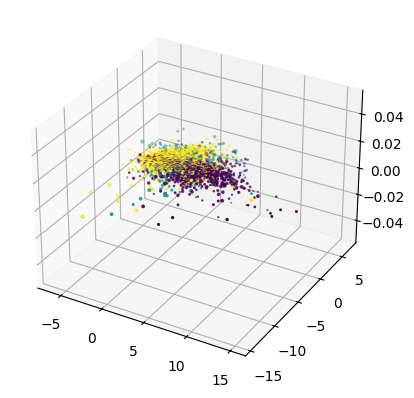

In [41]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
plt.scatter(X_pca[num_points[0]:num_points[1], 0], X_pca[num_points[0]:num_points[1], 1], X_pca[num_points[0]:num_points[1], 2], c=y[num_points[0]:num_points[1]],)